# 1. Problem Understanding

We want to predict house prices using:

Area Income

House Age

Number of Rooms

Number of Bedrooms

Area Population

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Load dataset

In [2]:
df = pd.read_csv("../data/usa_housing.csv")
df

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386
...,...,...,...,...,...,...,...
4995,60567.944140,7.830362,6.137356,3.46,22837.361035,1.060194e+06,USNS Williams\nFPO AP 30153-7653
4996,78491.275435,6.999135,6.576763,4.02,25616.115489,1.482618e+06,"PSC 9258, Box 8489\nAPO AA 42991-3352"
4997,63390.686886,7.250591,4.805081,2.13,33266.145490,1.030730e+06,"4215 Tracy Garden Suite 076\nJoshualand, VA 01..."
4998,68001.331235,5.534388,7.130144,5.44,42625.620156,1.198657e+06,USS Wallace\nFPO AE 73316


## Exploratory Data Analysis

### 1. Data inspection

In [3]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


In [4]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df['Address'].nunique()

5000

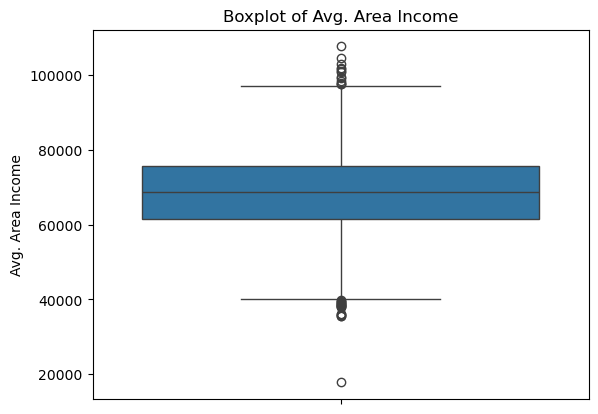

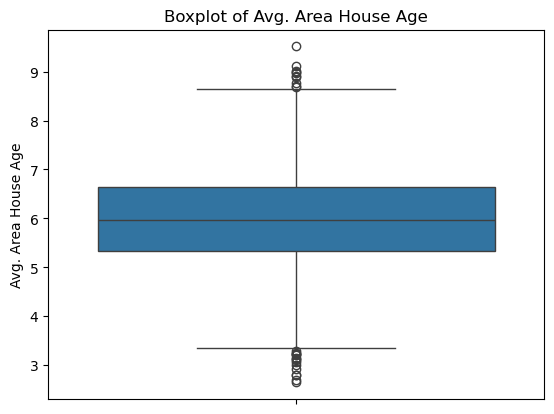

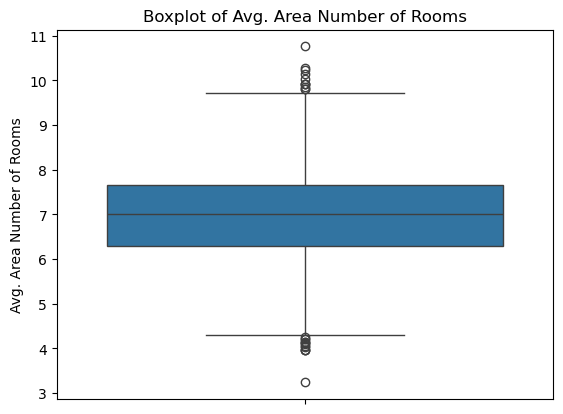

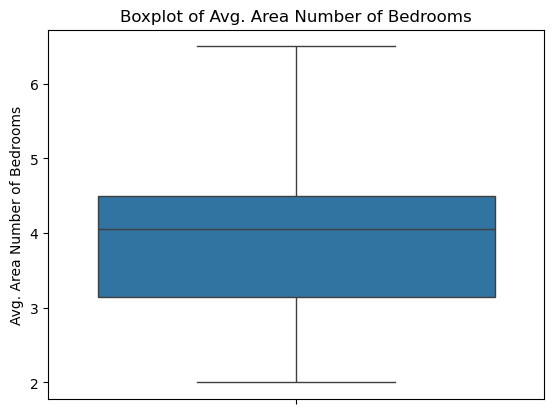

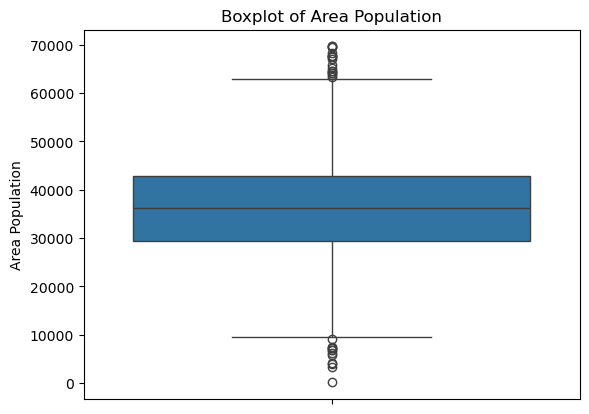

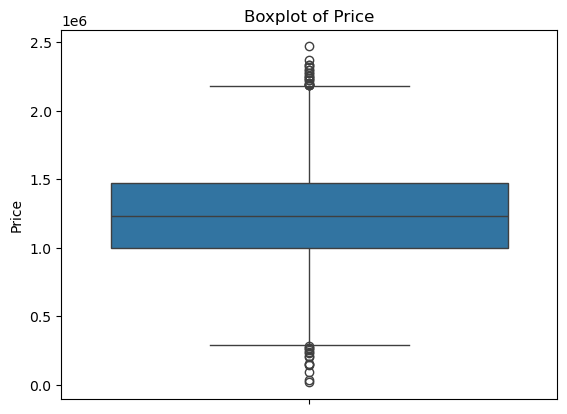

In [7]:
for col in df.select_dtypes(include='number').columns:
    sns.boxplot(data=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

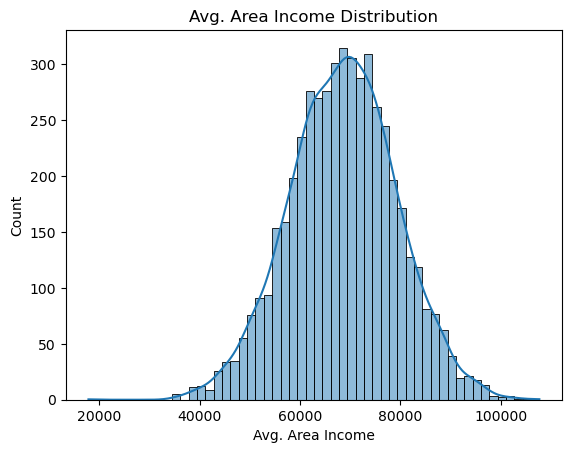

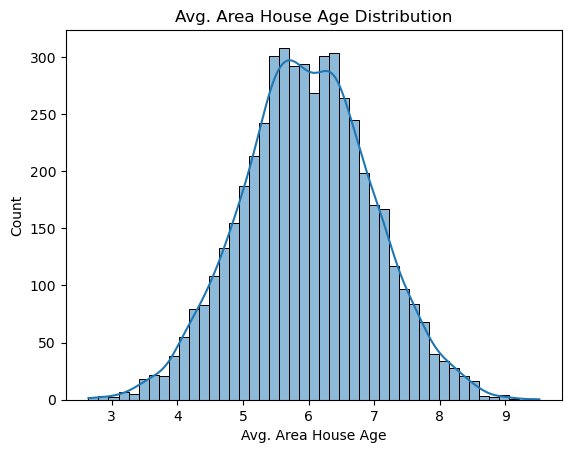

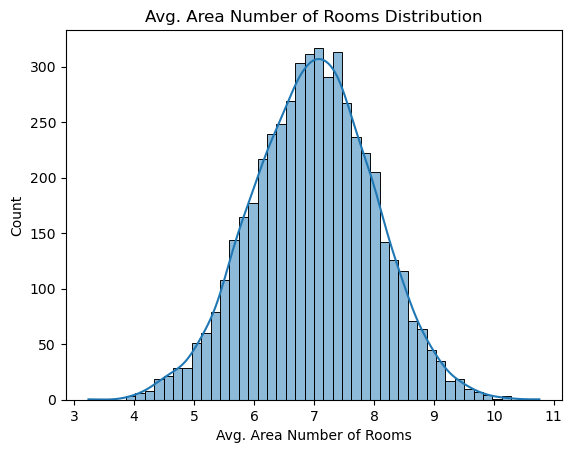

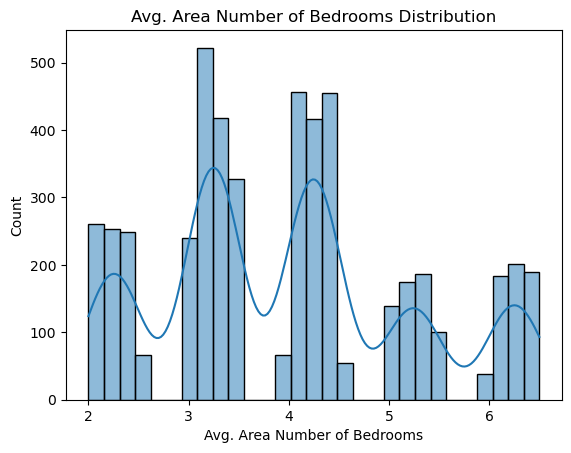

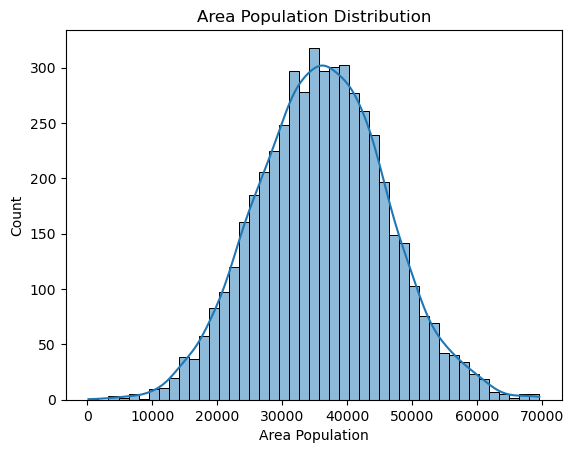

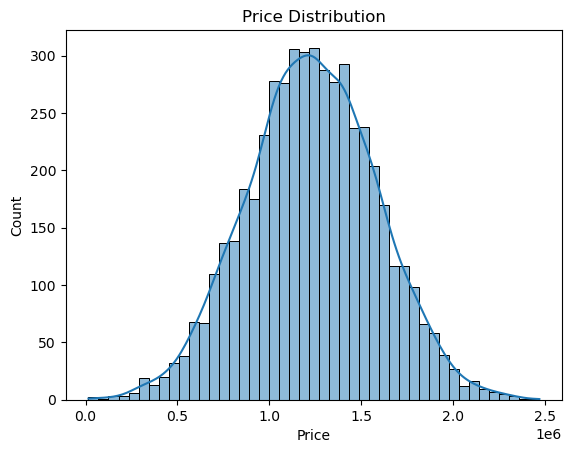

In [12]:
for col in df.select_dtypes(include='number').columns:
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f"{col} Distribution")
    plt.show()

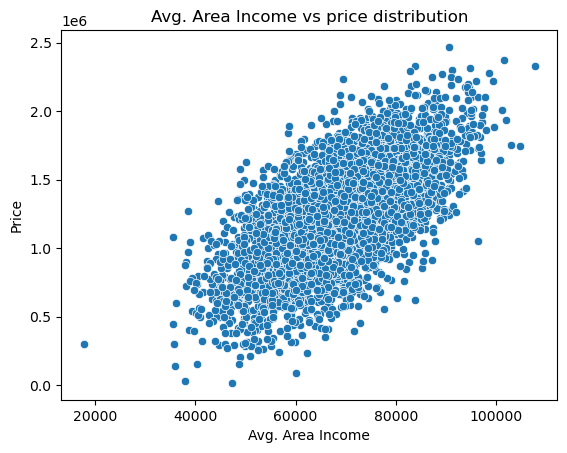

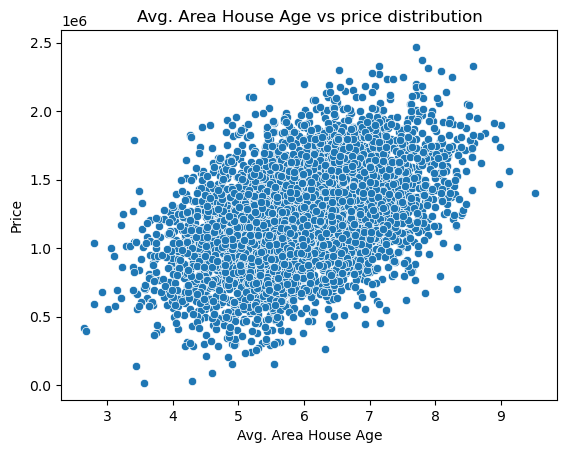

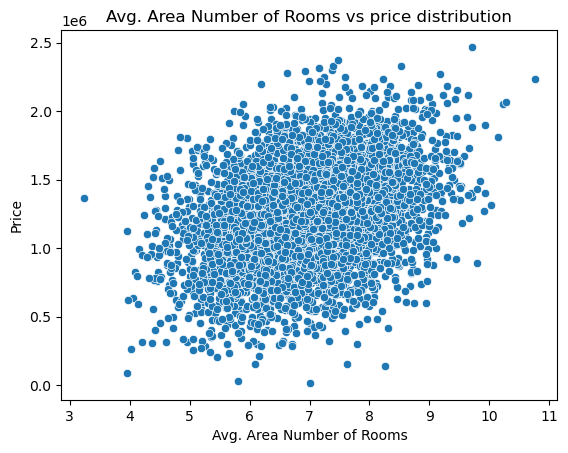

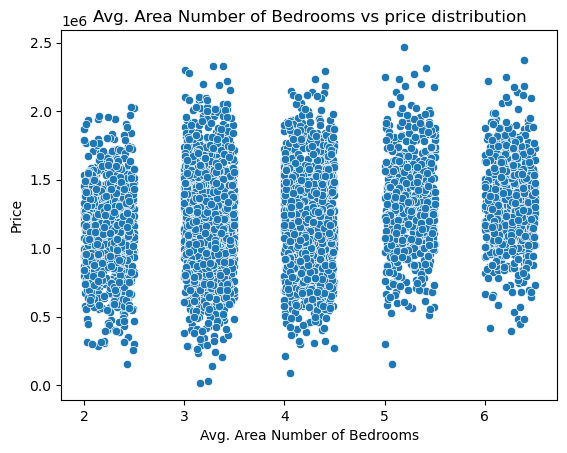

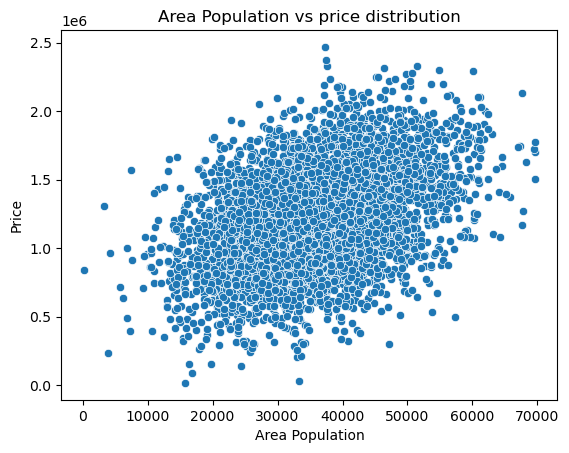

In [9]:
features = df.drop(columns=["Price", "Address"]).columns

for col in features:
    sns.scatterplot(data=df, x=col, y="Price")
    plt.title(f"{col} vs price distribution")
    plt.show()

In [10]:
df.drop(columns='Address').corr()['Price'].sort_values(ascending=False)

Price                           1.000000
Avg. Area Income                0.639734
Avg. Area House Age             0.452543
Area Population                 0.408556
Avg. Area Number of Rooms       0.335664
Avg. Area Number of Bedrooms    0.171071
Name: Price, dtype: float64

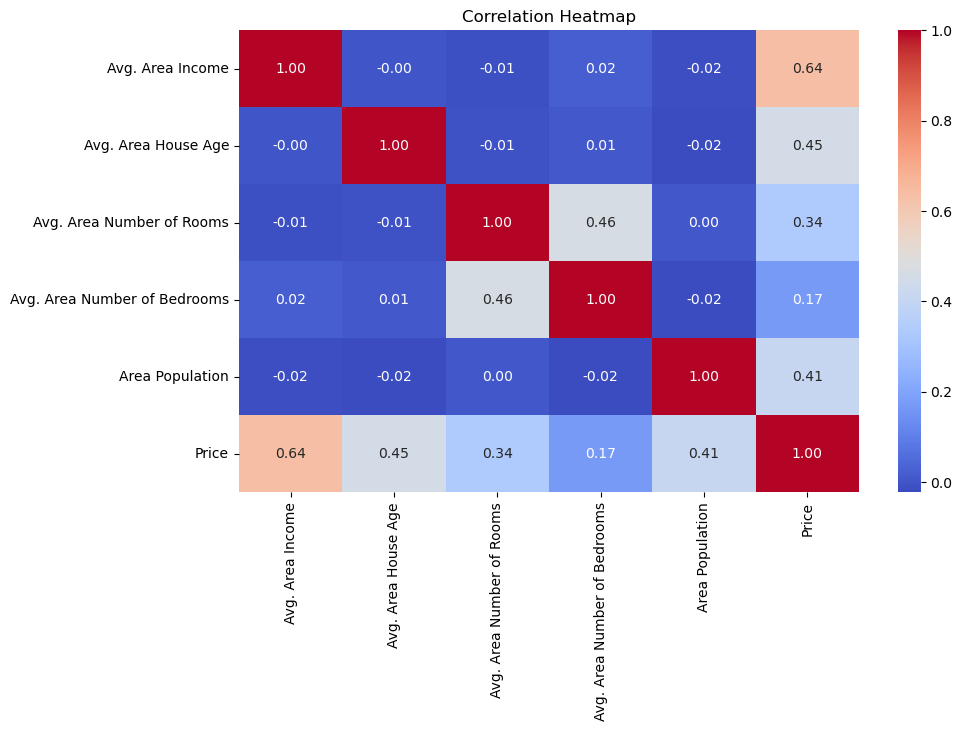

In [11]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.drop(columns='Address').corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

### 2. Data cleaning and transfromation
- No cleaning or transformation needed

## Seperate X and Y

In [14]:
X = df.drop(columns=["Price", "Address"])
Y = df["Price"]

## Train / Test Split

In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

## Model training

In [16]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


## Making predictions

In [18]:
Y_test_pred = model.predict(X_test)

## Model evaluation

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print("MAE:", mean_absolute_error(Y_test, Y_test_pred))
print("MSE:", mean_squared_error(Y_test, Y_test_pred))
print("R2:", r2_score(Y_test, Y_test_pred))

MAE: 80879.09723487175
MSE: 10089009300.890957
R2: 0.9179971706834578


In [23]:
#evaluating the model - overfit, underfit, or good fit?
Y_test_prediction = model.predict(X_test)
Y_train_prediction = model.predict(X_train)
test_r2 = r2_score(Y_test, Y_test_prediction)
train_r2 = r2_score(Y_train, Y_train_prediction)

print("Model R-squared on Test Set:", test_r2)
print("Model R-squared on Train Set:", train_r2)

Model R-squared on Test Set: 0.9179971706834578
Model R-squared on Train Set: 0.9179787435623722


In [ ]:
plt.scatter(y_test, y_test_prediction, color='#5FA89D')
plt.xlabel("Actual Delivery Time")
plt.ylabel("Predicted Delivery Time")
plt.title("Delivery Time Prediction")
plt.show()

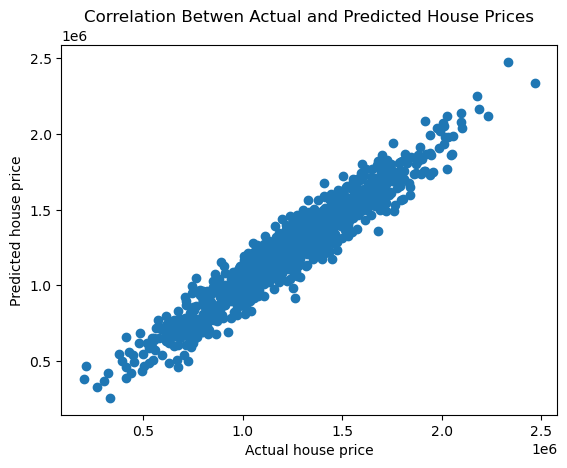

In [25]:
plt.scatter(Y_test, Y_test_prediction)
plt.title("Correlation Betwen Actual and Predicted House Prices")
plt.xlabel("Actual house price")
plt.ylabel("Predicted house price")
plt.show()

In [ ]:
#calculating residuals
residuals = Y_test - Y_test_prediction

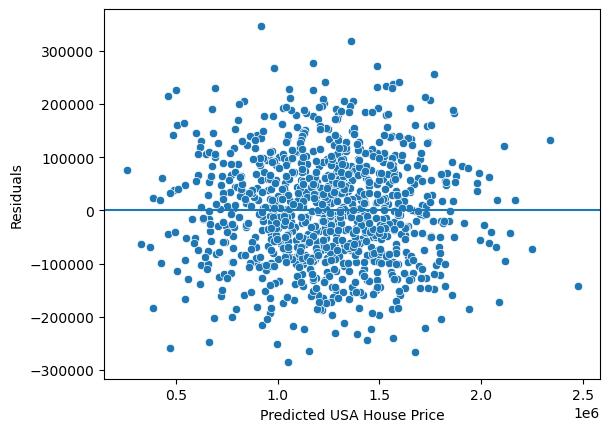

In [ ]:
sns.scatterplot(x=Y_test_prediction, y=residuals)
plt.axhline(0)
plt.xlabel('Predicted USA House Price')
plt.ylabel('Residuals')
plt.show()

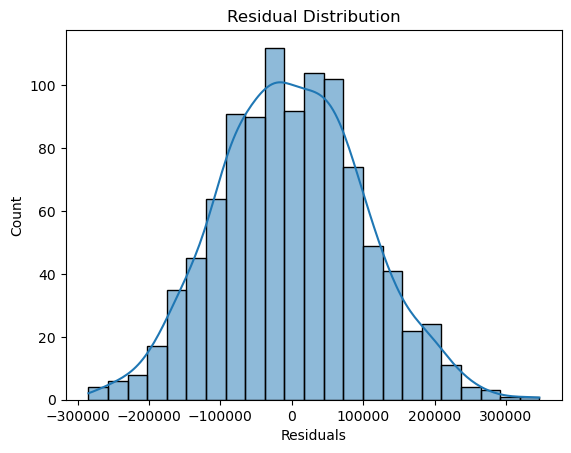

In [30]:
sns.histplot(residuals, kde=True)
plt.xlabel('Residuals')
plt.title('Residual Distribution')
plt.show()

10. Save Model